# Waste Classification: Shared Evaluation
Devan Rowland

**Running the notebook.**  This notebook scores all 12 trained models the same way, four architectures trained with three seeds each, on three image sets: the TrashNet validation split, the TrashNet test split, and the team's phone photos.  It runs in Google Colab on a graphics processing unit (GPU).  The trained weights and the photos live in the team's shared Google Drive folder, so that folder needs a shortcut in My Drive before the first run.  In Drive, open Shared with me, right-click Waste_Classification_Project, and choose Organize, then Add shortcut, then My Drive.  The notebook downloads the team's shared code from GitHub and the TrashNet images, and it prepares every image with the shared code's own preparation steps, so each model sees images prepared exactly the way they were in training.  Every result is saved to an Evaluation folder inside the shared folder, where the whole team can open it.  The score cells reload the results from there, so they still work after Colab clears its memory.  A full run takes about 15 minutes, mostly reading the photos and scoring the models.  Nothing here trains a model, so a rerun gives the same scores, though the timings vary a little.  The setup comes first.

In [9]:
import torch

# Check PyTorch and GPU
print(f"PyTorch {torch.__version__}")
gpu_available = torch.cuda.is_available()
print(f"GPU available: {gpu_available}")
if gpu_available:
    gpu_name = torch.cuda.get_device_name(0)
    print(gpu_name)

PyTorch 2.14.1+cu130
GPU available: True
Tesla T4


## Setup

**Shared code.**  The setup cell downloads the team's GitHub repository, or updates it if it's already there, and prints which commit it's using.  Importing the shared code instead of copying it keeps this notebook's image preparation identical to training, which is the point of a shared evaluation.

**TrashNet.**  The same cell downloads the TrashNet images and unzips the resized set, the folder the split file's image paths point to.  It should count 2,527 images.  Rerunning the cell skips anything already downloaded.

The predictions come next.

In [10]:
import glob
import os
import subprocess
import sys
import zipfile

# Set download locations
repo_url = (
    "https://github.com/viviantothewu-web/trashnet-waste-classification"
)
trashnet_url = "https://github.com/garythung/trashnet.git"
repo_folder = "/content/trashnet-waste-classification"
trashnet_folder = f"{repo_folder}/trashnet"
image_folder = f"{trashnet_folder}/data/dataset-resized"
image_zip_path = f"{trashnet_folder}/data/dataset-resized.zip"

# Clone shared repo
if not os.path.exists(repo_folder):
    repo_command = ["git", "clone", repo_url, repo_folder]
    subprocess.run(repo_command, check=True)

# Pull latest shared code
pull_command = ["git", "-C", repo_folder, "pull"]
subprocess.run(pull_command, check=True)

# Clone TrashNet images
if not os.path.exists(trashnet_folder):
    trashnet_command = ["git", "clone", trashnet_url, trashnet_folder]
    subprocess.run(trashnet_command, check=True)

# Unzip resized images
if not os.path.exists(image_folder):
    image_zip = zipfile.ZipFile(image_zip_path)
    image_zip.extractall(f"{trashnet_folder}/data")
    image_zip.close()

# Count TrashNet images
image_paths = glob.glob(f"{image_folder}/*/*.jpg")
image_total = len(image_paths)
print(f"TrashNet images: {image_total}")

# Move into shared repo
os.chdir(repo_folder)
sys.path.insert(0, repo_folder)

# Print shared code version
log_command = ["git", "log", "-1", "--date=short", "--format=%h %cd %s"]
log_result = subprocess.run(log_command, capture_output=True, text=True)
commit_line = log_result.stdout
commit_text = commit_line.strip()
print(f"Shared code commit: {commit_text}")

TrashNet images: 2527
Shared code commit: fe59640 2026-11-22 add file


## Predictions

**Trained models.**  Each trainer saved two weight files per pretrained model, and the stage 2 file is the finished model.  The custom CNN has one file, customcnn_seed plus the seed number.  For every seed folder and architecture, the notebook rebuilds the network with the shared builder, Joshua's CustomCNN class for the custom CNN, loads the finished weights, and switches it to evaluation mode.  Evaluation mode turns off the parts that only act during training, such as dropout.  A file that doesn't exist is skipped with a note.

**TrashNet splits.**  Each model scores the validation split, the 379 images each trainer used to pick their best checkpoint, and the test split, 380 images no training step ever looked at.  The validation accuracies should match each trainer's training log to within one percentage point, which confirms the weights and image preparation loaded correctly.

**Phone photos.**  The photo cell reads every file in the six class folders inside Data/real_world_test, and the folder a photo sits in is its true class.  It checks the set first: photos per class and photographer, names that break the team's pattern, like cardboard_P3_001.jpg, repeated photo numbers, identical files, and files it can't open.  It also counts two things a phone stores inside each photo.  One is the rotation tag, a note about which way the camera was held.  The image library ignores that tag, so the notebook turns each photo upright with it first, or a photo taken sideways would reach the models on its side.  The other is the GPS location, which shows where the photo was taken, so any photo that still has one should be cleaned before the photos are shared outside the team.  The notebook only counts those locations and never prints them.  Each upright photo then gets exactly the preparation the TrashNet images get, taken straight from the shared code's validation loader, so photos and TrashNet images are resized and normalized the same way.  The check is saved as eval_photo_audit.csv.

**Predictions.**  Each model looks at every image and gives six probabilities, one per class.  A softmax produces them, turning the network's raw scores into probabilities that add up to 1.  The class with the highest probability is the prediction.  Every image becomes one row in the prediction file, with the image set, architecture, seed, image path, true class, predicted class, whether it was right, and the six probabilities.  Each run also checks that the images came out in the same order as their list, so every row's path belongs to the right image.  To skip the test split or the photos, change `run_test_split` or `run_photo_set` to `False` in the predictions cell.

**Size and speed.**  The last run cell counts each model's parameters, the learned numbers inside it, and reads the size of its weight file in megabytes as Google Drive counts them.  It then times one image and a batch of 32 on the GPU.  Each timing warms the model up with 10 runs, then reports the median of 30 timed runs.  All 12 models are timed in the same session on the same GPU, so their speeds can be compared.

The scores follow the run cells.

In [11]:
import hashlib
import io
import numpy as np
import os
import pandas as pd
import time
import torch
from PIL import Image
from PIL import ImageOps
from src.custom_cnn import CustomCNN
from src.data_pipeline import CLASS_NAMES
from src.data_pipeline import CLASS_TO_IDX
from src.transfer_learning import create_pretrained_model
from torch.utils.data import DataLoader
from torch.utils.data import TensorDataset

def pick_device():
    # Prefer GPU when present
    if torch.cuda.is_available():
        return torch.device("cuda")
    return torch.device("cpu")

def describe_device(device):
    # Name GPU or CPU
    if device.type == "cuda":
        return torch.cuda.get_device_name(0)
    return "cpu"

def make_file_name(architecture, seed):
    # Name final weight file
    if architecture == "customcnn":
        return f"customcnn_seed{seed}.pth"
    return f"{architecture}_seed{seed}_stage2.pth"

def make_checkpoint_path(project_folder, architecture, seed):
    # Build checkpoint path
    file_name = make_file_name(architecture, seed)
    checkpoint_path = f"{project_folder}/Seed_{seed}/{file_name}"
    return checkpoint_path

def build_architecture(architecture):
    # Pick shared builder
    if architecture == "customcnn":
        return CustomCNN(num_classes=6)
    return create_pretrained_model(architecture)

def load_trained_model(architecture, checkpoint_path, device):
    # Build shared architecture
    model = build_architecture(architecture)

    # Load trained weights
    trained_weights = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(trained_weights, strict=True)
    model.to(device)
    model.eval()
    return model

def predict_images(model, loader, device):
    # Collect class probabilities
    probability_batches = []
    label_batches = []
    with torch.no_grad():
        for images, labels in loader:
            device_images = images.to(device)
            logits = model(device_images)
            probabilities = torch.softmax(logits, dim=1)
            cpu_probabilities = probabilities.cpu()
            probability_batches.append(cpu_probabilities)
            label_batches.append(labels)

    # Stack batch results
    probability_tensor = torch.cat(probability_batches)
    label_tensor = torch.cat(label_batches)
    all_probabilities = probability_tensor.numpy()
    all_labels = label_tensor.numpy()
    return all_probabilities, all_labels

def make_prediction_table(
    split_rows,
    probabilities,
    labels,
    eval_set,
    architecture,
    seed,
):
    # Pick predicted classes
    class_array = np.array(CLASS_NAMES)
    predicted_indexes = np.argmax(probabilities, axis=1)
    predicted_classes = class_array[predicted_indexes]
    true_classes = class_array[labels]
    correct_flags = predicted_classes == true_classes

    # Check list order
    split_class_column = split_rows["class"]
    split_classes = split_class_column.to_numpy()
    order_matches = np.array_equal(true_classes, split_classes)
    print(f"Images match list order: {order_matches}")

    # Build prediction rows
    split_path_column = split_rows["filepath"]
    split_filepaths = split_path_column.to_numpy()
    table_columns = {
        "eval_set": eval_set,
        "architecture": architecture,
        "seed": seed,
        "filepath": split_filepaths,
        "true_class": true_classes,
        "pred_class": predicted_classes,
        "correct": correct_flags,
    }
    prediction_table = pd.DataFrame(table_columns)

    # Add class probabilities
    for class_index in range(6):
        class_name = CLASS_NAMES[class_index]
        prediction_table[f"prob_{class_name}"] = probabilities[:, class_index]
    return prediction_table

def evaluate_checkpoint(
    architecture,
    seed,
    checkpoint_path,
    eval_sets,
    device,
):
    # Skip missing checkpoint
    if not os.path.exists(checkpoint_path):
        print(f"Not found yet: {architecture} seed {seed}")
        return []

    # Load trained model
    model = load_trained_model(architecture, checkpoint_path, device)

    # Predict each set
    model_tables = []
    for eval_set, loader, split_rows in eval_sets:
        probabilities, labels = predict_images(model, loader, device)
        prediction_table = make_prediction_table(
            split_rows,
            probabilities,
            labels,
            eval_set,
            architecture,
            seed,
        )
        correct_column = prediction_table["correct"]
        accuracy = correct_column.mean()
        accuracy_percent = accuracy * 100
        run_label = f"{architecture} seed {seed}, {eval_set}"
        print(f"{run_label}: {accuracy_percent:.2f}%")
        model_tables.append(prediction_table)
    return model_tables

def count_parameters(model):
    # Count learned numbers
    parameter_counts = []
    for parameter in model.parameters():
        parameter_count = parameter.numel()
        parameter_counts.append(parameter_count)
    parameter_total = sum(parameter_counts)
    return parameter_total

def wait_for_gpu(device):
    # Finish queued GPU work
    if device.type == "cuda":
        torch.cuda.synchronize()

def time_model(model, device, batch_size):
    # Make random image batch
    random_images = torch.rand(batch_size, 3, 224, 224, device=device)

    # Warm up model
    with torch.no_grad():
        for warmup_number in range(10):
            model(random_images)

    # Time 30 runs
    run_seconds = []
    with torch.no_grad():
        for run_number in range(30):
            wait_for_gpu(device)
            start_time = time.perf_counter()
            model(random_images)
            wait_for_gpu(device)
            end_time = time.perf_counter()
            elapsed_seconds = end_time - start_time
            run_seconds.append(elapsed_seconds)

    # Return median milliseconds
    median_seconds = np.median(run_seconds)
    median_milliseconds = median_seconds * 1000
    return median_milliseconds

def measure_checkpoint(architecture, seed, checkpoint_path, device):
    # Skip missing checkpoint
    if not os.path.exists(checkpoint_path):
        print(f"Not found yet: {architecture} seed {seed}")
        return []

    # Load trained model
    model = load_trained_model(architecture, checkpoint_path, device)

    # Measure model size
    parameter_total = count_parameters(model)
    file_bytes = os.path.getsize(checkpoint_path)
    file_megabytes = file_bytes / 1048576

    # Measure model speed
    single_milliseconds = time_model(model, device, batch_size=1)
    batch_milliseconds = time_model(model, device, batch_size=32)
    per_image_milliseconds = batch_milliseconds / 32
    run_label = f"{architecture} seed {seed}"
    print(f"{run_label}: {single_milliseconds:.2f} ms for one image")

    # Return measurement row
    device_label = describe_device(device)
    size_speed_row = {
        "architecture": architecture,
        "seed": seed,
        "parameters": parameter_total,
        "file_mb": file_megabytes,
        "device": device_label,
        "batch1_ms": single_milliseconds,
        "batch32_ms": batch_milliseconds,
        "batch32_ms_per_image": per_image_milliseconds,
    }
    return [size_speed_row]

def list_photo_files(photo_folder):
    # Walk photo folders
    relative_paths = []
    for folder_path, child_names, file_names in os.walk(photo_folder):
        child_names.sort()
        for file_name in sorted(file_names):
            file_path = os.path.join(folder_path, file_name)
            relative_path = os.path.relpath(file_path, photo_folder)
            forward_path = relative_path.replace(os.sep, "/")
            relative_paths.append(forward_path)
    return relative_paths

def read_photo_name(file_name):
    # Split team file name
    name_parts = os.path.splitext(file_name)
    name_stem = name_parts[0]
    stem_parts = name_stem.split("_")
    if len(stem_parts) != 3:
        return "unknown", -1, ""
    name_class, photographer, number_text = stem_parts

    # Check label and number
    label_letter = photographer[:1].upper()
    label_digits = photographer[1:]
    label_ok = label_letter == "P" and label_digits.isdigit()
    if not label_ok or not number_text.isdigit():
        return "unknown", -1, ""
    photographer_label = photographer.upper()
    photo_number = int(number_text)
    class_text = name_class.lower()
    return photographer_label, photo_number, class_text

def read_photo(photo_path):
    # Read file bytes
    with open(photo_path, "rb") as photo_file:
        file_bytes = photo_file.read()
    file_digest = hashlib.md5(file_bytes)
    file_hash = file_digest.hexdigest()

    # Read phone tags
    orientation_key = 274
    gps_key = 34853
    latitude_key = 2
    byte_stream = io.BytesIO(file_bytes)
    photo = Image.open(byte_stream)
    photo_tags = photo.getexif()
    orientation_tag = photo_tags.get(orientation_key, 0)
    gps_tags = photo_tags.get_ifd(gps_key)
    has_gps = latitude_key in gps_tags

    # Turn photo upright
    upright_photo = ImageOps.exif_transpose(photo)
    rgb_photo = upright_photo.convert("RGB")
    return rgb_photo, orientation_tag, has_gps, file_hash

def audit_photo_file(photo_folder, relative_path, eval_transform):
    # Read folder and name
    path_parts = relative_path.split("/")
    folder_class = path_parts[0].lower()
    file_name = path_parts[-1]
    name_parts = os.path.splitext(file_name)
    extension = name_parts[1].lower()
    name_facts = read_photo_name(file_name)
    photographer, photo_number, name_class = name_facts

    # Start audit row
    audit_row = {
        "filepath": f"Data/real_world_test/{relative_path}",
        "file_name": file_name,
        "class": folder_class,
        "photographer": photographer,
        "photo_number": photo_number,
        "pattern_ok": photographer != "unknown",
        "class_matches": name_class == folder_class,
        "nested": len(path_parts) > 2,
        "width": 0,
        "height": 0,
        "shape": "",
        "orientation_tag": 0,
        "has_gps": False,
        "file_hash": "",
        "used": False,
        "problem": "",
    }

    # Skip files outside classes
    in_class_folder = len(path_parts) > 1 and folder_class in CLASS_NAMES
    if not in_class_folder:
        audit_row["problem"] = "outside class folders"
        return audit_row, None
    if extension not in [".jpg", ".jpeg", ".png"]:
        audit_row["problem"] = f"file type {extension}"
        return audit_row, None

    # Open photo file
    photo_path = f"{photo_folder}/{relative_path}"
    try:
        photo_facts = read_photo(photo_path)
    except Exception as read_error:
        error_name = type(read_error).__name__
        audit_row["problem"] = f"can't open ({error_name})"
        return audit_row, None
    rgb_photo, orientation_tag, has_gps, file_hash = photo_facts

    # Apply shared preparation
    photo_tensor = eval_transform(rgb_photo)
    photo_width, photo_height = rgb_photo.size
    photo_shape = "landscape"
    if photo_height > photo_width:
        photo_shape = "portrait"
    audit_row["width"] = photo_width
    audit_row["height"] = photo_height
    audit_row["shape"] = photo_shape
    audit_row["orientation_tag"] = orientation_tag
    audit_row["has_gps"] = has_gps
    audit_row["file_hash"] = file_hash
    audit_row["used"] = True
    return audit_row, photo_tensor

def prepare_photos(photo_folder, eval_transform):
    # Audit every photo
    audit_rows = []
    photo_tensors = []
    relative_paths = list_photo_files(photo_folder)
    for relative_path in relative_paths:
        audit_row, photo_tensor = audit_photo_file(
            photo_folder,
            relative_path,
            eval_transform,
        )
        audit_rows.append(audit_row)
        if photo_tensor is not None:
            photo_tensors.append(photo_tensor)
    audit_table = pd.DataFrame(audit_rows)
    return audit_table, photo_tensors

def print_photo_audit(audit_table):
    # Count usable photos
    used_mask = audit_table["used"]
    used_rows = audit_table[used_mask]
    count_view = pd.crosstab(
        used_rows["class"],
        used_rows["photographer"],
        margins=True,
        margins_name="total",
    )
    count_text = count_view.to_string()
    print("Usable photos by class and photographer")
    print(count_text)

    # List skipped files
    skipped_mask = audit_table["problem"] != ""
    skipped_rows = audit_table[skipped_mask]
    skipped_total = len(skipped_rows)
    print(f"Files skipped: {skipped_total}")
    for skipped_row in skipped_rows.itertuples():
        print(f"  {skipped_row.filepath}: {skipped_row.problem}")

    # List naming problems
    pattern_flags = used_rows["pattern_ok"]
    class_flags = used_rows["class_matches"]
    off_pattern_mask = ~pattern_flags
    wrong_class_mask = pattern_flags & ~class_flags
    nested_mask = used_rows["nested"]
    name_checks = [
        ("Names off the pattern", off_pattern_mask),
        ("Name class differs from folder", wrong_class_mask),
        ("Photos in subfolders", nested_mask),
    ]
    for check_label, check_mask in name_checks:
        check_rows = used_rows[check_mask]
        check_total = len(check_rows)
        print(f"{check_label}: {check_total}")
        for check_row in check_rows.itertuples():
            print(f"  {check_row.filepath}")

    # Find repeated numbers
    named_rows = used_rows[pattern_flags]
    number_columns = ["class", "photographer", "photo_number"]
    repeat_mask = named_rows.duplicated(subset=number_columns, keep=False)
    repeat_rows = named_rows[repeat_mask]
    repeat_total = len(repeat_rows)
    print(f"Repeated photo numbers: {repeat_total}")
    for repeat_row in repeat_rows.itertuples():
        print(f"  {repeat_row.filepath}")

    # Find identical files
    hash_mask = used_rows.duplicated(subset=["file_hash"], keep=False)
    identical_rows = used_rows[hash_mask]
    identical_total = len(identical_rows)
    print(f"Identical files: {identical_total}")
    for identical_row in identical_rows.itertuples():
        print(f"  {identical_row.filepath}")

    # Count phone tags
    rotated_flags = used_rows["orientation_tag"] > 1
    portrait_flags = used_rows["shape"] == "portrait"
    tag_table = pd.DataFrame()
    tag_table["photographer"] = used_rows["photographer"]
    tag_table["photos"] = 1
    tag_table["rotation_tag"] = rotated_flags
    tag_table["gps_location"] = used_rows["has_gps"]
    tag_table["portrait"] = portrait_flags
    tag_groups = tag_table.groupby("photographer")
    tag_view = tag_groups.sum()
    tag_text = tag_view.to_string()
    print("Rotation tags, GPS locations and portrait photos")
    print(tag_text)

def make_photo_loader(audit_table, photo_tensors):
    # Keep usable photo rows
    used_mask = audit_table["used"]
    photo_rows = audit_table[used_mask]
    class_column = photo_rows["class"]
    class_indexes = class_column.map(CLASS_TO_IDX)
    index_array = class_indexes.to_numpy()

    # Stack photo tensors
    photo_stack = torch.stack(photo_tensors)
    photo_labels = torch.tensor(index_array)
    photo_dataset = TensorDataset(photo_stack, photo_labels)
    photo_loader = DataLoader(photo_dataset, batch_size=32, shuffle=False)
    return photo_rows, photo_loader

In [12]:
import os
from google.colab import drive
from src.data_pipeline import create_dataloaders

# Connect to Drive
drive.mount("/content/drive")
project_folder = "/content/drive/MyDrive/Waste_Classification_Project"
save_folder = f"{project_folder}/Evaluation"
photo_folder = f"{project_folder}/Data/real_world_test"

# Check shared folders
folder_found = os.path.exists(project_folder)
photo_folder_found = os.path.exists(photo_folder)
print(f"Shared Drive folder found: {folder_found}")
print(f"Photo folder found: {photo_folder_found}")
if folder_found:
    os.makedirs(save_folder, exist_ok=True)

# Borrow shared preparation
split_path = "data_splits/trashnet_split.csv"
shared_loaders = create_dataloaders(
    split_path,
    img_size=224,
    batch_size=32,
    training_seed=0,
)
validation_loader = shared_loaders[1]
validation_dataset = validation_loader.dataset
eval_transform = validation_dataset.transform
print(eval_transform)

# Check and prepare photos
audit_table, photo_tensors = prepare_photos(photo_folder, eval_transform)
photo_total = len(photo_tensors)
photos_ready = photo_total > 0
print(f"Photos ready: {photo_total}")

# Report photo check
photo_rows = None
photo_loader = None
if photos_ready:
    print_photo_audit(audit_table)
    photo_rows, photo_loader = make_photo_loader(audit_table, photo_tensors)
    audit_path = f"{save_folder}/eval_photo_audit.csv"
    audit_table.to_csv(audit_path, index=False)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Shared Drive folder found: True
Photo folder found: True
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)
Photos ready: 304
Usable photos by class and photographer
photographer   P1   P2   P3  total
class                             
cardboard      17   17   17     51
glass          17   17   17     51
metal          17   17   17     51
paper          17   17   17     51
plastic        16   17   17     50
trash          16   17   17     50
total         100  102  102    304
Files skipped: 0
Names off the pattern: 0
Name class differs from folder: 0
Photos in subfolders: 0
Repeated photo numbers: 0
Identical files: 0
Rotation tags, GPS locations and portrait photos
              photos  rotation_tag  gps_location  portrait
photograph

In [13]:
import os
import pandas as pd
from google.colab import drive
from src.data_pipeline import create_dataloaders

# Connect to Drive
drive.mount("/content/drive")
project_folder = "/content/drive/MyDrive/Waste_Classification_Project"
save_folder = f"{project_folder}/Evaluation"

# Check shared folder shortcut
folder_found = os.path.exists(project_folder)
print(f"Shared Drive folder found: {folder_found}")
if folder_found:
    os.makedirs(save_folder, exist_ok=True)

# Load shared split loaders
split_path = "data_splits/trashnet_split.csv"
train_loader, validation_loader, test_loader = create_dataloaders(
    split_path,
    img_size=224,
    batch_size=32,
    training_seed=0,
)

# Load split file rows
split_table = pd.read_csv(split_path)
validation_mask = split_table["split"] == "validation"
test_mask = split_table["split"] == "test"
validation_rows = split_table[validation_mask]
test_rows = split_table[test_mask]

# Pick evaluation sets
run_test_split = True
run_photo_set = True
validation_set = ("trashnet_validation", validation_loader, validation_rows)
eval_sets = [validation_set]
if run_test_split:
    test_set = ("trashnet_test", test_loader, test_rows)
    eval_sets.append(test_set)
if run_photo_set and photos_ready:
    photo_set = ("phone_photos", photo_loader, photo_rows)
    eval_sets.append(photo_set)

# Predict with saved models
device = pick_device()
prediction_tables = []
for seed in [0, 1, 2]:
    for architecture in ["customcnn", "vgg16", "resnet50", "mobilenetv2"]:
        checkpoint_path = make_checkpoint_path(
            project_folder,
            architecture,
            seed,
        )
        model_tables = evaluate_checkpoint(
            architecture,
            seed,
            checkpoint_path,
            eval_sets,
            device,
        )
        prediction_tables.extend(model_tables)

# Save prediction table
all_predictions = pd.concat(prediction_tables)
predictions_path = f"{save_folder}/eval_predictions.csv"
all_predictions.to_csv(predictions_path, index=False)
row_total = len(all_predictions)
print(f"Saved {row_total} prediction rows")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Shared Drive folder found: True
Images match list order: True
customcnn seed 0, trashnet_validation: 72.82%
Images match list order: True
customcnn seed 0, trashnet_test: 71.58%
Images match list order: True
customcnn seed 0, phone_photos: 15.79%
Images match list order: True
vgg16 seed 0, trashnet_validation: 87.07%
Images match list order: True
vgg16 seed 0, trashnet_test: 84.21%
Images match list order: True
vgg16 seed 0, phone_photos: 36.51%
Images match list order: True
resnet50 seed 0, trashnet_validation: 93.14%
Images match list order: True
resnet50 seed 0, trashnet_test: 90.79%
Images match list order: True
resnet50 seed 0, phone_photos: 38.49%
Images match list order: True
mobilenetv2 seed 0, trashnet_validation: 90.50%
Images match list order: True
mobilenetv2 seed 0, trashnet_test: 88.95%
Images match list order: True
mobilenetv2 seed 0, phone_pho

In [14]:
import os
import pandas as pd
from google.colab import drive

# Connect to Drive
drive.mount("/content/drive")
project_folder = "/content/drive/MyDrive/Waste_Classification_Project"
save_folder = f"{project_folder}/Evaluation"

# Check shared folder shortcut
folder_found = os.path.exists(project_folder)
print(f"Shared Drive folder found: {folder_found}")
if folder_found:
    os.makedirs(save_folder, exist_ok=True)

# Measure every saved model
device = pick_device()
size_speed_rows = []
for seed in [0, 1, 2]:
    for architecture in ["customcnn", "vgg16", "resnet50", "mobilenetv2"]:
        checkpoint_path = make_checkpoint_path(
            project_folder,
            architecture,
            seed,
        )
        model_rows = measure_checkpoint(
            architecture,
            seed,
            checkpoint_path,
            device,
        )
        size_speed_rows.extend(model_rows)

# Save measurement table
size_speed_table = pd.DataFrame(size_speed_rows)
size_speed_path = f"{save_folder}/eval_size_speed.csv"
size_speed_table.to_csv(size_speed_path, index=False)
row_total = len(size_speed_table)
print(f"Saved {row_total} size and speed rows")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Shared Drive folder found: True
customcnn seed 0: 0.88 ms for one image
vgg16 seed 0: 10.27 ms for one image
resnet50 seed 0: 6.81 ms for one image
mobilenetv2 seed 0: 7.81 ms for one image
customcnn seed 1: 0.59 ms for one image
vgg16 seed 1: 10.45 ms for one image
resnet50 seed 1: 9.74 ms for one image
mobilenetv2 seed 1: 6.19 ms for one image
customcnn seed 2: 0.62 ms for one image
vgg16 seed 2: 10.18 ms for one image
resnet50 seed 2: 6.69 ms for one image
mobilenetv2 seed 2: 5.81 ms for one image
Saved 12 size and speed rows


## Scores

**Accuracy and macro F1.**  The cells below reload the saved files from Drive.  Accuracy is the share of images classified correctly.  Macro F1 gives each of the six classes an equal vote.  A class's F1 balances its precision, how often a prediction of that class is right, against its recall, how many of that class's images the model finds.  Macro F1 matters because TrashNet's trash class is small, so a high accuracy can hide a weak class.

**Training-log check.**  Each validation accuracy is compared with the best validation accuracy in its trainer's log, and the two should agree within one percentage point.  Small gaps come from running on a different machine with different software versions, while a bigger one means the log or the weight file needs a second look.  The cell reads the training log in each Seed folder and skips any value that isn't a number, with a note.  The manual list in that cell holds numbers from runs outside the training notebook: Vivian's seed 0 results as her training notebook printed them, and Joshua's seed 1 custom CNN result.  A manual number wins over a log, and each line says which one it used.

**Seeds.**  The mean and standard deviation over the three seeds are printed for every image set.  The standard deviation divides by n - 1, the usual choice for a small sample.

**Generalization gap.**  The gap table puts each architecture's TrashNet test accuracy next to its phone photo accuracy, and the gap is the drop in percentage points.  The gap is worked out seed by seed before averaging, so its standard deviation shows how much the drop itself varies.  The chart after it shows the same comparison as bars, with the standard deviation as error bars and a dashed line at 1 in 6, the accuracy of guessing.

**Classes and confusion matrices.**  The class tables show recall and F1 for every class, averaged over the three seeds, for the TrashNet test split and the phone photos.  A confusion matrix is a grid of true class against predicted class, so the cells off the diagonal show which classes get mixed up.  Each architecture's matrix adds up its three seeds.

In [15]:
import pandas as pd
from google.colab import drive
from sklearn.metrics import f1_score

# Load saved predictions
drive.mount("/content/drive")
project_folder = "/content/drive/MyDrive/Waste_Classification_Project"
save_folder = f"{project_folder}/Evaluation"
all_predictions = pd.read_csv(f"{save_folder}/eval_predictions.csv")

# Score each model
class_names = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]
summary_rows = []
group_columns = ["eval_set", "architecture", "seed"]
model_groups = all_predictions.groupby(group_columns, sort=False)
for (eval_set, architecture, seed), model_rows in model_groups:
    true_classes = model_rows["true_class"]
    predicted_classes = model_rows["pred_class"]
    correct_column = model_rows["correct"]
    correct_total = int(correct_column.sum())
    image_total = len(model_rows)
    accuracy = correct_total / image_total
    macro_f1 = f1_score(
        true_classes,
        predicted_classes,
        labels=class_names,
        average="macro",
        zero_division=0,
    )
    summary_row = {
        "eval_set": eval_set,
        "architecture": architecture,
        "seed": seed,
        "images": image_total,
        "correct": correct_total,
        "accuracy_percent": accuracy * 100,
        "macro_f1_percent": macro_f1 * 100,
    }
    summary_rows.append(summary_row)

# Save model scores
summary_table = pd.DataFrame(summary_rows)
summary_path = f"{save_folder}/eval_summary.csv"
summary_table.to_csv(summary_path, index=False)

# Print scores by set
set_order = ["trashnet_validation", "trashnet_test", "phone_photos"]
for eval_set in set_order:
    set_mask = summary_table["eval_set"] == eval_set
    set_rows = summary_table[set_mask]
    set_text = set_rows.to_string(index=False, float_format="%.2f")
    print(set_text)
    print()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
           eval_set architecture  seed  images  correct  accuracy_percent  macro_f1_percent
trashnet_validation    customcnn     0     379      276             72.82             70.21
trashnet_validation        vgg16     0     379      330             87.07             84.14
trashnet_validation     resnet50     0     379      353             93.14             92.25
trashnet_validation  mobilenetv2     0     379      343             90.50             88.33
trashnet_validation    customcnn     1     379      266             70.18             66.75
trashnet_validation        vgg16     1     379      334             88.13             86.83
trashnet_validation     resnet50     1     379      351             92.61             91.72
trashnet_validation  mobilenetv2     1     379      343             90.50             89.11
trashnet_validation    customcnn     2     

In [16]:
import os
import pandas as pd
from google.colab import drive

def read_seed_log(log_path, seed, log_columns):
    # Read one trainer log
    try:
        seed_log = pd.read_csv(log_path)
    except Exception:
        print(f"Seed {seed} log can't be read, so it's skipped")
        return None
    has_columns = set(log_columns).issubset(seed_log.columns)
    if not has_columns:
        print(f"Seed {seed} log has other columns, so it's skipped")
        return None

    # Flag non-number values
    seed_columns = seed_log[log_columns]
    best_column = seed_columns["stage2_best_val"]
    best_numbers = pd.to_numeric(best_column, errors="coerce")
    blank_total = int(best_numbers.isna().sum())
    if blank_total > 0:
        print(f"Seed {seed} log, values that aren't numbers: {blank_total}")
    log_source = f"seed {seed} log"
    sourced_columns = seed_columns.assign(source=log_source)
    return sourced_columns

# Load saved scores
drive.mount("/content/drive")
project_folder = "/content/drive/MyDrive/Waste_Classification_Project"
save_folder = f"{project_folder}/Evaluation"
summary_table = pd.read_csv(f"{save_folder}/eval_summary.csv")

# Set manual log numbers
manual_rows = [
    ("vgg16", 0, 0.8707),
    ("resnet50", 0, 0.9314),
    ("mobilenetv2", 0, 0.9050),
    ("customcnn", 0, 0.7282),
    ("customcnn", 1, 0.7018),
]
log_columns = ["architecture", "seed", "stage2_best_val"]
manual_table = pd.DataFrame(manual_rows, columns=log_columns)
manual_sourced = manual_table.assign(source="manual")

# Load trainer logs
log_tables = [manual_sourced]
for seed in [0, 1, 2]:
    log_path = f"{project_folder}/Seed_{seed}/seed{seed}_training_log.csv"
    if os.path.exists(log_path):
        seed_columns = read_seed_log(log_path, seed, log_columns)
        log_tables.append(seed_columns)

# Combine trainer logs
combined_logs = pd.concat(log_tables)
architecture_text = combined_logs["architecture"].astype(str)
architecture_names = architecture_text.str.lower()
seed_column = combined_logs["seed"]
seed_numbers = pd.to_numeric(seed_column, errors="coerce")
best_column = combined_logs["stage2_best_val"]
best_values = pd.to_numeric(best_column, errors="coerce")
percent_mask = best_values > 1
fraction_values = best_values.mask(percent_mask, best_values / 100)
cleaned_logs = combined_logs.assign(
    architecture=architecture_names,
    seed=seed_numbers,
    stage2_best_val=fraction_values,
)
usable_logs = cleaned_logs.dropna(subset=["seed", "stage2_best_val"])
typed_logs = usable_logs.astype({"seed": "int64"})
log_keys = ["architecture", "seed"]
logged_table = typed_logs.drop_duplicates(subset=log_keys)

# Compare with training logs
validation_mask = summary_table["eval_set"] == "trashnet_validation"
validation_scores = summary_table[validation_mask]
check_table = validation_scores.merge(
    logged_table,
    on=log_keys,
    how="left",
)
for check_row in check_table.itertuples():
    run_label = f"{check_row.architecture} seed {check_row.seed}"
    has_log = not pd.isna(check_row.stage2_best_val)
    if has_log:
        logged_percent = check_row.stage2_best_val * 100
        measured_percent = check_row.accuracy_percent
        point_gap = abs(measured_percent - logged_percent)
        check_passed = point_gap <= 1.0
        logged_text = f"{logged_percent:.2f}% ({check_row.source})"
        score_text = f"log {logged_text}, here {measured_percent:.2f}%"
        print(f"{run_label}: {score_text}, match {check_passed}")
    if not has_log:
        print(f"{run_label}: no training log number yet")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Seed 0 log, values that aren't numbers: 3
customcnn seed 0: log 72.82% (manual), here 72.82%, match True
vgg16 seed 0: log 87.07% (manual), here 87.07%, match True
resnet50 seed 0: log 93.14% (manual), here 93.14%, match True
mobilenetv2 seed 0: log 90.50% (manual), here 90.50%, match True
customcnn seed 1: log 70.18% (manual), here 70.18%, match True
vgg16 seed 1: log 88.13% (seed 1 log), here 88.13%, match True
resnet50 seed 1: log 92.61% (seed 1 log), here 92.61%, match True
mobilenetv2 seed 1: log 90.50% (seed 1 log), here 90.50%, match True
customcnn seed 2: log 72.30% (seed 2 log), here 72.30%, match True
vgg16 seed 2: log 87.34% (seed 2 log), here 87.34%, match True
resnet50 seed 2: log 91.29% (seed 2 log), here 91.29%, match True
mobilenetv2 seed 2: log 91.03% (seed 2 log), here 91.03%, match True


In [17]:
import pandas as pd
from google.colab import drive

# Load saved scores
drive.mount("/content/drive")
project_folder = "/content/drive/MyDrive/Waste_Classification_Project"
save_folder = f"{project_folder}/Evaluation"
summary_table = pd.read_csv(f"{save_folder}/eval_summary.csv")

# Average over seeds
score_columns = ["accuracy_percent", "macro_f1_percent"]
seed_groups = summary_table.groupby(["eval_set", "architecture"])
seed_scores = seed_groups[score_columns]
mean_scores = seed_scores.mean()
sd_scores = seed_scores.std(ddof=1)
seed_totals = seed_groups.size()

# Build seed table
seed_table = pd.DataFrame()
seed_table["seeds"] = seed_totals
seed_table["accuracy_mean"] = mean_scores["accuracy_percent"]
seed_table["accuracy_sd"] = sd_scores["accuracy_percent"]
seed_table["macro_f1_mean"] = mean_scores["macro_f1_percent"]
seed_table["macro_f1_sd"] = sd_scores["macro_f1_percent"]

# Put rows in order
set_order = ["trashnet_validation", "trashnet_test", "phone_photos"]
architecture_order = ["customcnn", "vgg16", "resnet50", "mobilenetv2"]
reading_order = pd.MultiIndex.from_product(
    [set_order, architecture_order],
    names=["eval_set", "architecture"],
)
ordered_table = seed_table.reindex(reading_order)
present_table = ordered_table.dropna(subset=["seeds"])
seed_counts = present_table["seeds"].astype(int)
printed_table = present_table.assign(seeds=seed_counts)

# Save and print table
seed_path = f"{save_folder}/eval_seed_average.csv"
printed_table.to_csv(seed_path)
seed_text = printed_table.to_string(float_format="%.2f")
print(seed_text)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
                                  seeds  accuracy_mean  accuracy_sd  macro_f1_mean  macro_f1_sd
eval_set            architecture                                                               
trashnet_validation customcnn         3          71.77         1.40          69.07         2.01
                    vgg16             3          87.51         0.55          85.44         1.35
                    resnet50          3          92.35         0.95          90.80         2.07
                    mobilenetv2       3          90.68         0.30          89.09         0.75
trashnet_test       customcnn         3          71.93         0.61          67.80         1.27
                    vgg16             3          83.33         1.30          78.48         1.47
                    resnet50          3          89.82         1.24          86.05         0.35
       

In [18]:
import pandas as pd
from google.colab import drive

# Load saved scores
drive.mount("/content/drive")
project_folder = "/content/drive/MyDrive/Waste_Classification_Project"
save_folder = f"{project_folder}/Evaluation"
summary_table = pd.read_csv(f"{save_folder}/eval_summary.csv")

# Pair test and photos
test_mask = summary_table["eval_set"] == "trashnet_test"
photo_mask = summary_table["eval_set"] == "phone_photos"
test_scores = summary_table[test_mask]
photo_scores = summary_table[photo_mask]
paired_scores = test_scores.merge(
    photo_scores,
    on=["architecture", "seed"],
    suffixes=("_test", "_photos"),
)

# Work out seed gaps
test_accuracy = paired_scores["accuracy_percent_test"]
photo_accuracy = paired_scores["accuracy_percent_photos"]
test_f1 = paired_scores["macro_f1_percent_test"]
photo_f1 = paired_scores["macro_f1_percent_photos"]
seed_gaps = pd.DataFrame()
seed_gaps["architecture"] = paired_scores["architecture"]
seed_gaps["test_accuracy"] = test_accuracy
seed_gaps["photo_accuracy"] = photo_accuracy
seed_gaps["accuracy_gap"] = test_accuracy - photo_accuracy
seed_gaps["test_macro_f1"] = test_f1
seed_gaps["photo_macro_f1"] = photo_f1
seed_gaps["macro_f1_gap"] = test_f1 - photo_f1

# Average over seeds
gap_groups = seed_gaps.groupby("architecture")
mean_values = gap_groups.mean()
sd_values = gap_groups.std(ddof=1)
seed_totals = gap_groups.size()

# Build gap table
mean_table = mean_values.add_suffix("_mean")
sd_table = sd_values.add_suffix("_sd")
joined_table = mean_table.join(sd_table)
joined_table.insert(0, "seeds", seed_totals)
architecture_order = ["customcnn", "vgg16", "resnet50", "mobilenetv2"]
ordered_table = joined_table.reindex(architecture_order)
present_table = ordered_table.dropna(subset=["seeds"])
seed_counts = present_table["seeds"].astype(int)
gap_table = present_table.assign(seeds=seed_counts)

# Save gap table
gap_path = f"{save_folder}/eval_gap.csv"
gap_table.to_csv(gap_path, index_label="architecture")

# Print results tables
display_names = {
    "customcnn": "Custom CNN",
    "vgg16": "VGG16",
    "resnet50": "ResNet50",
    "mobilenetv2": "MobileNetV2",
}
for metric in ["accuracy", "macro_f1"]:
    print(f"{metric} (%): TrashNet test | phone photos | gap in points")
    for architecture, gap_row in gap_table.iterrows():
        test_mean = gap_row[f"test_{metric}_mean"]
        test_sd = gap_row[f"test_{metric}_sd"]
        photo_mean = gap_row[f"photo_{metric}_mean"]
        photo_sd = gap_row[f"photo_{metric}_sd"]
        gap_mean = gap_row[f"{metric}_gap_mean"]
        gap_sd = gap_row[f"{metric}_gap_sd"]
        test_text = f"{test_mean:.2f} ± {test_sd:.2f}"
        photo_text = f"{photo_mean:.2f} ± {photo_sd:.2f}"
        gap_text = f"{gap_mean:.2f} ± {gap_sd:.2f}"
        row_text = f"{test_text} | {photo_text} | {gap_text}"
        display_name = display_names[architecture]
        print(f"  {display_name}: {row_text}")
    print()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
accuracy (%): TrashNet test | phone photos | gap in points
  Custom CNN: 71.93 ± 0.61 | 16.12 ± 0.87 | 55.81 ± 1.35
  VGG16: 83.33 ± 1.30 | 32.35 ± 3.84 | 50.99 ± 3.70
  ResNet50: 89.82 ± 1.24 | 36.84 ± 2.57 | 52.98 ± 1.35
  MobileNetV2: 90.00 ± 0.95 | 34.54 ± 2.00 | 55.46 ± 1.55

macro_f1 (%): TrashNet test | phone photos | gap in points
  Custom CNN: 67.80 ± 1.27 | 13.70 ± 1.16 | 54.10 ± 1.65
  VGG16: 78.48 ± 1.47 | 30.60 ± 3.57 | 47.89 ± 2.69
  ResNet50: 86.05 ± 0.35 | 35.37 ± 3.08 | 50.68 ± 2.73
  MobileNetV2: 85.86 ± 1.84 | 31.68 ± 2.36 | 54.18 ± 1.08



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


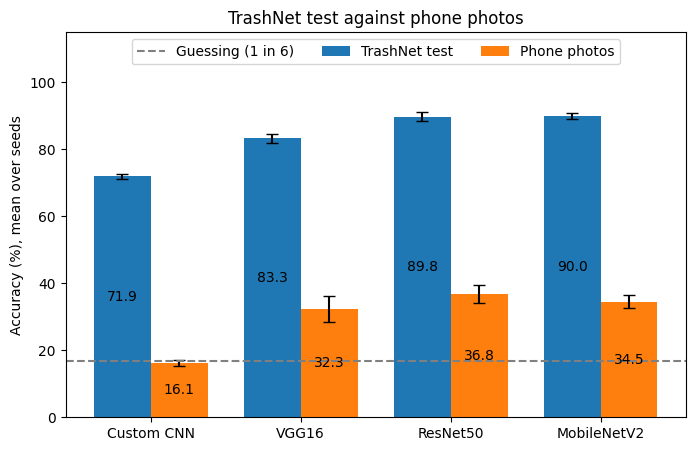

In [19]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import drive

# Load saved gap table
drive.mount("/content/drive")
project_folder = "/content/drive/MyDrive/Waste_Classification_Project"
save_folder = f"{project_folder}/Evaluation"
gap_table = pd.read_csv(f"{save_folder}/eval_gap.csv")

# Set bar positions
display_names = {
    "customcnn": "Custom CNN",
    "vgg16": "VGG16",
    "resnet50": "ResNet50",
    "mobilenetv2": "MobileNetV2",
}
architecture_names = gap_table["architecture"]
tick_labels = architecture_names.map(display_names)
bar_positions = np.arange(len(gap_table))
bar_width = 0.38
test_positions = bar_positions - bar_width / 2
photo_positions = bar_positions + bar_width / 2

# Plot test against photos
plt.figure(figsize=(8, 5))
test_bars = plt.bar(
    test_positions,
    gap_table["test_accuracy_mean"],
    bar_width,
    yerr=gap_table["test_accuracy_sd"],
    capsize=4,
    label="TrashNet test",
)
photo_bars = plt.bar(
    photo_positions,
    gap_table["photo_accuracy_mean"],
    bar_width,
    yerr=gap_table["photo_accuracy_sd"],
    capsize=4,
    label="Phone photos",
)
plt.bar_label(test_bars, fmt="%.1f", label_type="center")
plt.bar_label(photo_bars, fmt="%.1f", label_type="center")
plt.axhline(100 / 6, color="gray", linestyle="--", label="Guessing (1 in 6)")
plt.xticks(bar_positions, tick_labels)
plt.ylim(0, 115)
plt.ylabel("Accuracy (%), mean over seeds")
plt.title("TrashNet test against phone photos")
plt.legend(loc="upper center", ncol=3)
plt.show()

In [20]:
import pandas as pd
from google.colab import drive
from sklearn.metrics import precision_recall_fscore_support

# Load saved predictions
drive.mount("/content/drive")
project_folder = "/content/drive/MyDrive/Waste_Classification_Project"
save_folder = f"{project_folder}/Evaluation"
all_predictions = pd.read_csv(f"{save_folder}/eval_predictions.csv")

# Score each class
class_names = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]
class_rows = []
group_columns = ["eval_set", "architecture", "seed"]
model_groups = all_predictions.groupby(group_columns, sort=False)
for (eval_set, architecture, seed), model_rows in model_groups:
    true_classes = model_rows["true_class"]
    predicted_classes = model_rows["pred_class"]
    class_scores = precision_recall_fscore_support(
        true_classes,
        predicted_classes,
        labels=class_names,
        zero_division=0,
    )
    precisions, recalls, f1_scores, supports = class_scores
    for class_index in range(6):
        class_row = {
            "eval_set": eval_set,
            "architecture": architecture,
            "seed": seed,
            "class": class_names[class_index],
            "images": supports[class_index],
            "precision_percent": precisions[class_index] * 100,
            "recall_percent": recalls[class_index] * 100,
            "f1_percent": f1_scores[class_index] * 100,
        }
        class_rows.append(class_row)

# Save class scores
class_table = pd.DataFrame(class_rows)
class_scores_path = f"{save_folder}/eval_class_scores.csv"
class_table.to_csv(class_scores_path, index=False)

# Print class averages
architecture_order = ["customcnn", "vgg16", "resnet50", "mobilenetv2"]
for shown_set in ["trashnet_test", "phone_photos"]:
    shown_mask = class_table["eval_set"] == shown_set
    shown_rows = class_table[shown_mask]
    if len(shown_rows) == 0:
        continue
    for score_column in ["recall_percent", "f1_percent"]:
        score_view = shown_rows.pivot_table(
            index="class",
            columns="architecture",
            values=score_column,
            aggfunc="mean",
        )
        ordered_view = score_view.reindex(columns=architecture_order)
        score_text = ordered_view.to_string(float_format="%.2f")
        print(f"{score_column} by class, mean over seeds, {shown_set}")
        print(score_text)
        print()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
recall_percent by class, mean over seeds, trashnet_test
architecture  customcnn  vgg16  resnet50  mobilenetv2
class                                                
cardboard         82.22  87.22     93.33        92.78
glass             67.11  77.19     91.23        91.23
metal             64.52  91.40     93.55        95.70
paper             87.64  88.39     91.39        91.39
plastic           66.67  85.84     91.78        91.32
trash             31.67  38.33     48.33        48.33

f1_percent by class, mean over seeds, trashnet_test
architecture  customcnn  vgg16  resnet50  mobilenetv2
class                                                
cardboard         87.57  90.97     93.85        93.03
glass             67.35  81.26     91.19        92.65
metal             69.28  85.15     93.03        91.98
paper             74.93  88.23     89.92        90.88
plasti

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


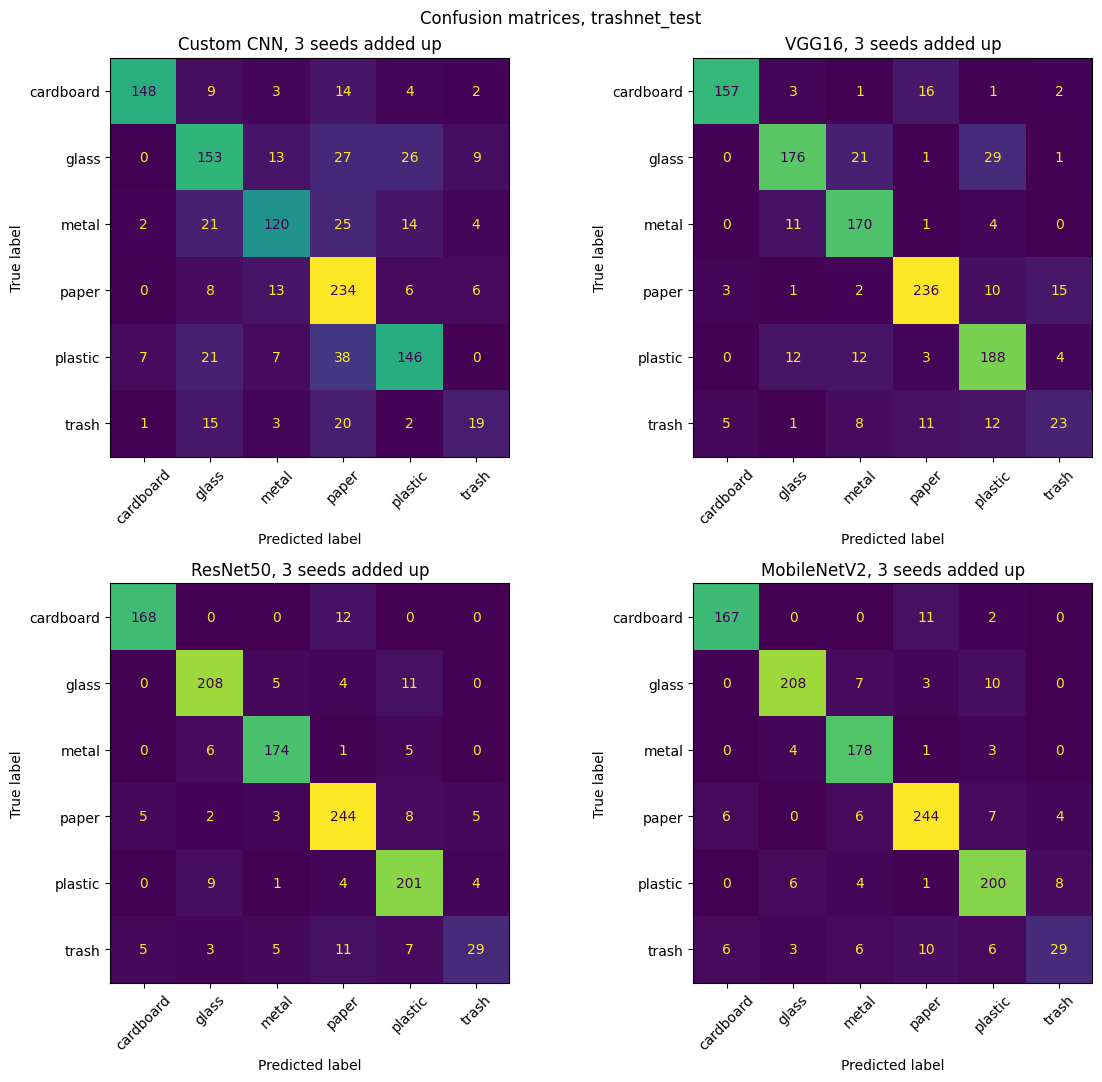

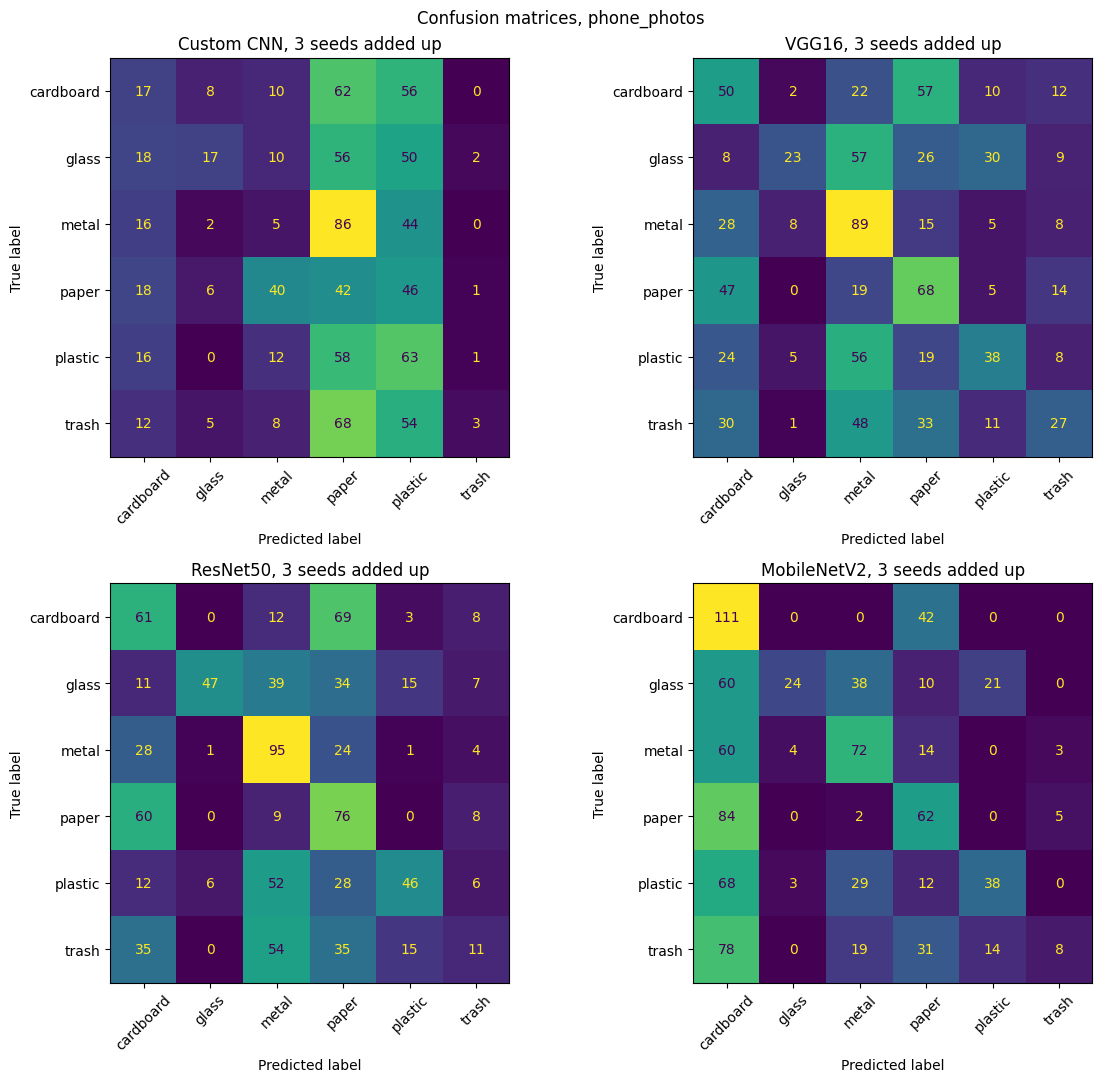

In [21]:
import matplotlib.pyplot as plt
import pandas as pd
from google.colab import drive
from sklearn.metrics import ConfusionMatrixDisplay

# Load saved predictions
drive.mount("/content/drive")
project_folder = "/content/drive/MyDrive/Waste_Classification_Project"
save_folder = f"{project_folder}/Evaluation"
all_predictions = pd.read_csv(f"{save_folder}/eval_predictions.csv")

# Plot summed confusion matrices
class_names = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]
architecture_order = ["customcnn", "vgg16", "resnet50", "mobilenetv2"]
display_names = {
    "customcnn": "Custom CNN",
    "vgg16": "VGG16",
    "resnet50": "ResNet50",
    "mobilenetv2": "MobileNetV2",
}
for shown_set in ["trashnet_test", "phone_photos"]:
    shown_mask = all_predictions["eval_set"] == shown_set
    shown_predictions = all_predictions[shown_mask]
    figure, axes = plt.subplots(2, 2, figsize=(12, 11))
    axis_list = axes.flatten()
    for axis, architecture in zip(axis_list, architecture_order):
        architecture_mask = shown_predictions["architecture"] == architecture
        architecture_rows = shown_predictions[architecture_mask]
        if len(architecture_rows) == 0:
            axis.set_axis_off()
            continue
        seed_column = architecture_rows["seed"]
        seed_total = seed_column.nunique()
        ConfusionMatrixDisplay.from_predictions(
            architecture_rows["true_class"],
            architecture_rows["pred_class"],
            labels=class_names,
            ax=axis,
            xticks_rotation=45,
            colorbar=False,
        )
        display_name = display_names[architecture]
        axis.set_title(f"{display_name}, {seed_total} seeds added up")
    figure.suptitle(f"Confusion matrices, {shown_set}")
    figure.tight_layout()
    plt.show()

## Error Analysis

**Photographers and shapes.**  The first cell splits phone photo accuracy by photographer and by the photo's shape once it's upright, portrait or landscape.  Every TrashNet image is a landscape photo, 512 by 384 pixels, of one object on white posterboard.  The shared preparation squeezes every image into a 224 by 224 square, which narrows the objects in a landscape photo but flattens them in a portrait one, so portrait photos show objects in proportions no training image had.

**Common mistakes.**  The next cell counts the most common wrong answers on the phone photos over all 12 models, and shows how often each architecture predicts each class.  The photos are spread close to evenly over the six classes, so a model that predicts one class far more than a sixth of the time is leaning on something those photos share, such as the background, rather than the object.

**Confidence.**  A model's confidence is its highest probability for an image.  Comparing average confidence with accuracy shows whether a model knows when it's wrong.  A model that stays confident on photos it gets wrong is overconfident, which matters for a real sorting bin, since a confident wrong answer can't be flagged for a person to check.

**Hardest photos.**  Every photo gets a count of how many of the 12 models got it right.  Photos no model gets right are the clearest failures to look at by eye, and the full list is saved as eval_photo_difficulty.csv.

In [22]:
import pandas as pd
from google.colab import drive

# Load saved results
drive.mount("/content/drive")
project_folder = "/content/drive/MyDrive/Waste_Classification_Project"
save_folder = f"{project_folder}/Evaluation"
all_predictions = pd.read_csv(f"{save_folder}/eval_predictions.csv")
photo_audit = pd.read_csv(f"{save_folder}/eval_photo_audit.csv")

# Join photo facts
photo_mask = all_predictions["eval_set"] == "phone_photos"
photo_predictions = all_predictions[photo_mask]
fact_columns = ["filepath", "photographer", "shape"]
fact_rows = photo_audit[fact_columns]
photo_facts = fact_rows.drop_duplicates(subset="filepath")
joined_predictions = photo_predictions.merge(photo_facts, on="filepath")
correct_numbers = joined_predictions["correct"].astype(float)
scored_predictions = joined_predictions.assign(correct=correct_numbers)

# Score by group
architecture_order = ["customcnn", "vgg16", "resnet50", "mobilenetv2"]
for fact_column in ["photographer", "shape"]:
    fact_view = scored_predictions.pivot_table(
        index="architecture",
        columns=fact_column,
        values="correct",
        aggfunc="mean",
    )
    percent_view = fact_view * 100
    ordered_view = percent_view.reindex(architecture_order)
    fact_text = ordered_view.to_string(float_format="%.2f")
    print(f"Photo accuracy (%) by {fact_column}, mean over seeds")
    print(fact_text)
    print()

# Count photos per group
used_mask = photo_audit["used"]
used_audit = photo_audit[used_mask]
count_view = pd.crosstab(used_audit["photographer"], used_audit["shape"])
count_text = count_view.to_string()
print("Photos by photographer and shape")
print(count_text)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Photo accuracy (%) by photographer, mean over seeds
photographer    P1    P2    P3
architecture                  
customcnn    17.67 19.28 11.44
vgg16        39.33 30.07 27.78
resnet50     46.67 33.01 31.05
mobilenetv2  44.67 29.08 30.07

Photo accuracy (%) by shape, mean over seeds
shape         landscape  portrait
architecture                     
customcnn         17.93     14.47
vgg16             37.70     27.46
resnet50          42.76     31.45
mobilenetv2       38.16     31.24

Photos by photographer and shape
shape         landscape  portrait
photographer                     
P1                  100         0
P2                   14        88
P3                   31        71


In [23]:
import pandas as pd
from google.colab import drive

# Load saved predictions
drive.mount("/content/drive")
project_folder = "/content/drive/MyDrive/Waste_Classification_Project"
save_folder = f"{project_folder}/Evaluation"
all_predictions = pd.read_csv(f"{save_folder}/eval_predictions.csv")
photo_mask = all_predictions["eval_set"] == "phone_photos"
photo_predictions = all_predictions[photo_mask]

# Count wrong answer pairs
wrong_mask = ~photo_predictions["correct"]
wrong_predictions = photo_predictions[wrong_mask]
pair_groups = wrong_predictions.groupby(["true_class", "pred_class"])
pair_counts = pair_groups.size()
sorted_pairs = pair_counts.sort_values(ascending=False)
top_pairs = sorted_pairs.head(10)
class_groups = photo_predictions.groupby("true_class")
class_totals = class_groups.size()
print("Most common wrong answers on phone photos, all models")
for (true_class, pred_class), pair_count in top_pairs.items():
    class_total = class_totals[true_class]
    pair_percent = pair_count / class_total * 100
    pair_text = f"{pair_count} of {class_total} ({pair_percent:.1f}%)"
    print(f"  {true_class} called {pred_class}: {pair_text}")

# Share predictions by class
class_names = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]
architecture_order = ["customcnn", "vgg16", "resnet50", "mobilenetv2"]
share_view = pd.crosstab(
    photo_predictions["pred_class"],
    photo_predictions["architecture"],
    normalize="columns",
)
percent_view = share_view * 100
class_view = percent_view.reindex(index=class_names, fill_value=0)
ordered_view = class_view.reindex(columns=architecture_order)
share_text = ordered_view.to_string(float_format="%.1f")
print()
print("Share of photo predictions by class (%), all seeds")
print(share_text)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Most common wrong answers on phone photos, all models
  cardboard called paper: 230 of 612 (37.6%)
  paper called cardboard: 209 of 612 (34.2%)
  trash called paper: 167 of 600 (27.8%)
  trash called cardboard: 155 of 600 (25.8%)
  plastic called metal: 149 of 600 (24.8%)
  glass called metal: 144 of 612 (23.5%)
  metal called paper: 139 of 612 (22.7%)
  metal called cardboard: 132 of 612 (21.6%)
  trash called metal: 129 of 600 (21.5%)
  glass called paper: 126 of 612 (20.6%)

Share of photo predictions by class (%), all seeds
architecture  customcnn  vgg16  resnet50  mobilenetv2
pred_class                                           
cardboard          10.6   20.5      22.7         50.5
glass               4.2    4.3       5.9          3.4
metal               9.3   31.9      28.6         17.5
paper              40.8   23.9      29.2         18.8
plastic      

In [24]:
import pandas as pd
from google.colab import drive

# Load saved predictions
drive.mount("/content/drive")
project_folder = "/content/drive/MyDrive/Waste_Classification_Project"
save_folder = f"{project_folder}/Evaluation"
all_predictions = pd.read_csv(f"{save_folder}/eval_predictions.csv")

# Find top probabilities
class_names = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]
probability_columns = []
for class_name in class_names:
    probability_columns.append(f"prob_{class_name}")
probability_table = all_predictions[probability_columns]
top_probabilities = probability_table.max(axis=1)
scored_predictions = all_predictions.assign(confidence=top_probabilities)

# Compare confidence and accuracy
confidence_rows = []
model_groups = scored_predictions.groupby(["eval_set", "architecture"])
for (eval_set, architecture), group_rows in model_groups:
    correct_flags = group_rows["correct"]
    wrong_rows = group_rows[~correct_flags]
    group_confidence = group_rows["confidence"]
    wrong_confidence = wrong_rows["confidence"]
    confidence_row = {
        "eval_set": eval_set,
        "architecture": architecture,
        "accuracy": correct_flags.mean() * 100,
        "mean_confidence": group_confidence.mean() * 100,
        "confidence_when_wrong": wrong_confidence.mean() * 100,
    }
    confidence_rows.append(confidence_row)
confidence_table = pd.DataFrame(confidence_rows)

# Save confidence table
confidence_path = f"{save_folder}/eval_confidence.csv"
confidence_table.to_csv(confidence_path, index=False)

# Print test and photos
for shown_set in ["trashnet_test", "phone_photos"]:
    set_mask = confidence_table["eval_set"] == shown_set
    set_rows = confidence_table[set_mask]
    set_text = set_rows.to_string(index=False, float_format="%.2f")
    print(set_text)
    print()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
     eval_set architecture  accuracy  mean_confidence  confidence_when_wrong
trashnet_test    customcnn     71.93            67.63                  50.04
trashnet_test  mobilenetv2     90.00            89.25                  64.57
trashnet_test     resnet50     89.82            94.10                  75.46
trashnet_test        vgg16     83.33            91.81                  76.38

    eval_set architecture  accuracy  mean_confidence  confidence_when_wrong
phone_photos    customcnn     16.12            75.19                  75.57
phone_photos  mobilenetv2     34.54            69.60                  65.72
phone_photos     resnet50     36.84            77.20                  74.19
phone_photos        vgg16     32.35            83.93                  83.05



In [25]:
import pandas as pd
from google.colab import drive

def pick_most_common(values):
    # Count repeated values
    value_counts = values.value_counts()
    return value_counts.index[0]

# Load saved results
drive.mount("/content/drive")
project_folder = "/content/drive/MyDrive/Waste_Classification_Project"
save_folder = f"{project_folder}/Evaluation"
all_predictions = pd.read_csv(f"{save_folder}/eval_predictions.csv")
photo_audit = pd.read_csv(f"{save_folder}/eval_photo_audit.csv")

# Count models right
photo_mask = all_predictions["eval_set"] == "phone_photos"
photo_predictions = all_predictions[photo_mask]
photo_groups = photo_predictions.groupby("filepath", sort=False)
top_predictions = photo_groups["pred_class"].agg(pick_most_common)
difficulty_table = pd.DataFrame()
difficulty_table["true_class"] = photo_groups["true_class"].first()
difficulty_table["models_right"] = photo_groups["correct"].sum()
difficulty_table["models_scored"] = photo_groups.size()
difficulty_table["top_prediction"] = top_predictions

# Add photo facts
fact_columns = ["filepath", "photographer", "shape"]
fact_rows = photo_audit[fact_columns]
photo_facts = fact_rows.drop_duplicates(subset="filepath")
difficulty_rows = difficulty_table.reset_index()
difficulty_joined = difficulty_rows.merge(photo_facts, on="filepath")

# Save photo difficulty
difficulty_path = f"{save_folder}/eval_photo_difficulty.csv"
difficulty_joined.to_csv(difficulty_path, index=False)

# Print right counts
right_counts = difficulty_joined["models_right"].value_counts()
sorted_counts = right_counts.sort_index()
count_text = sorted_counts.to_string()
print("Photos by number of models that got them right")
print(count_text)

# Print never right photos
never_mask = difficulty_joined["models_right"] == 0
never_rows = difficulty_joined[never_mask]
never_total = len(never_rows)
print()
print(f"Photos no model got right: {never_total}")
if never_total > 0:
    never_view = pd.crosstab(
        never_rows["true_class"],
        never_rows["photographer"],
    )
    never_text = never_view.to_string()
    print(never_text)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Photos by number of models that got them right
models_right
0     91
1     29
2     17
3     36
4     21
5     18
6     12
7     22
8     23
9     23
10     4
11     5
12     3

Photos no model got right: 91
photographer  P1  P2  P3
true_class              
cardboard      4   2   0
glass          6   9  12
metal          1   6   2
paper          1   2   0
plastic        0   6   7
trash          7  11  15


## Size and Speed

**Size and speed.**  The table lists each model's parameter count, weight file size and timings.  The two charts plot each architecture's accuracy, averaged over seeds, against its parameter count and against its time per image in a batch of 32, with one point for the TrashNet test split and one for the phone photos.

In [26]:
import pandas as pd
from google.colab import drive

# Load saved measurements
drive.mount("/content/drive")
project_folder = "/content/drive/MyDrive/Waste_Classification_Project"
save_folder = f"{project_folder}/Evaluation"
size_speed_table = pd.read_csv(f"{save_folder}/eval_size_speed.csv")

# Print size and speed
size_speed_text = size_speed_table.to_string(index=False, float_format="%.2f")
print(size_speed_text)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
architecture  seed  parameters  file_mb   device  batch1_ms  batch32_ms  batch32_ms_per_image
   customcnn     0       94022     0.36 Tesla T4       0.88       17.64                  0.55
       vgg16     0   134285126   512.27 Tesla T4      10.27      182.32                  5.70
    resnet50     0    23520326    90.03 Tesla T4       6.81      107.43                  3.36
 mobilenetv2     0     2231558     8.75 Tesla T4       7.81       31.17                  0.97
   customcnn     1       94022     0.36 Tesla T4       0.59       18.64                  0.58
       vgg16     1   134285126   512.27 Tesla T4      10.45      186.21                  5.82
    resnet50     1    23520326    90.03 Tesla T4       9.74      105.05                  3.28
 mobilenetv2     1     2231558     8.75 Tesla T4       6.19       30.41                  0.95
   customcnn     2       

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


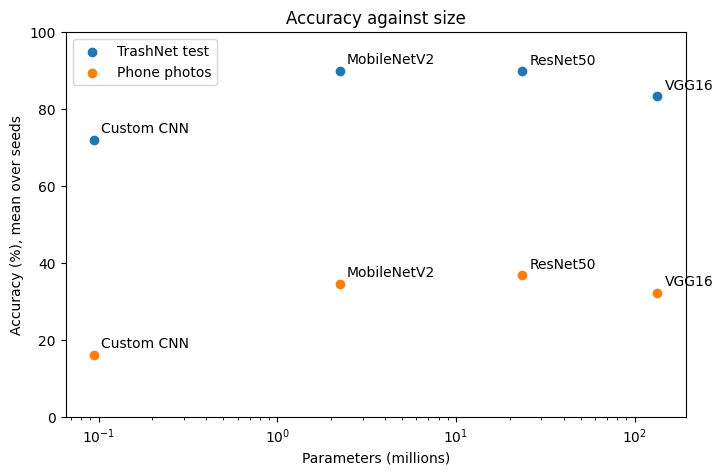

In [27]:
import matplotlib.pyplot as plt
import pandas as pd
from google.colab import drive

# Load saved results
drive.mount("/content/drive")
project_folder = "/content/drive/MyDrive/Waste_Classification_Project"
save_folder = f"{project_folder}/Evaluation"
summary_table = pd.read_csv(f"{save_folder}/eval_summary.csv")
size_speed_table = pd.read_csv(f"{save_folder}/eval_size_speed.csv")

# Average size over seeds
size_groups = size_speed_table.groupby("architecture")
parameter_groups = size_groups["parameters"]
mean_parameters = parameter_groups.mean()

# Plot accuracy against size
display_names = {
    "customcnn": "Custom CNN",
    "vgg16": "VGG16",
    "resnet50": "ResNet50",
    "mobilenetv2": "MobileNetV2",
}
chart_sets = [
    ("trashnet_test", "TrashNet test"),
    ("phone_photos", "Phone photos"),
]
plt.figure(figsize=(8, 5))
for chart_set, set_label in chart_sets:
    chart_mask = summary_table["eval_set"] == chart_set
    chart_scores = summary_table[chart_mask]
    score_groups = chart_scores.groupby("architecture")
    accuracy_groups = score_groups["accuracy_percent"]
    mean_accuracy = accuracy_groups.mean()
    architectures = mean_accuracy.index
    set_parameters = mean_parameters.reindex(architectures)
    parameter_millions = set_parameters / 1000000
    plt.scatter(parameter_millions, mean_accuracy, label=set_label)
    for architecture in architectures:
        point_x = parameter_millions[architecture]
        point_y = mean_accuracy[architecture]
        point = (point_x, point_y)
        plt.annotate(
            display_names[architecture],
            point,
            xytext=(5, 5),
            textcoords="offset points",
        )
plt.xscale("log")
plt.ylim(0, 100)
plt.xlabel("Parameters (millions)")
plt.ylabel("Accuracy (%), mean over seeds")
plt.title("Accuracy against size")
plt.legend()
plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


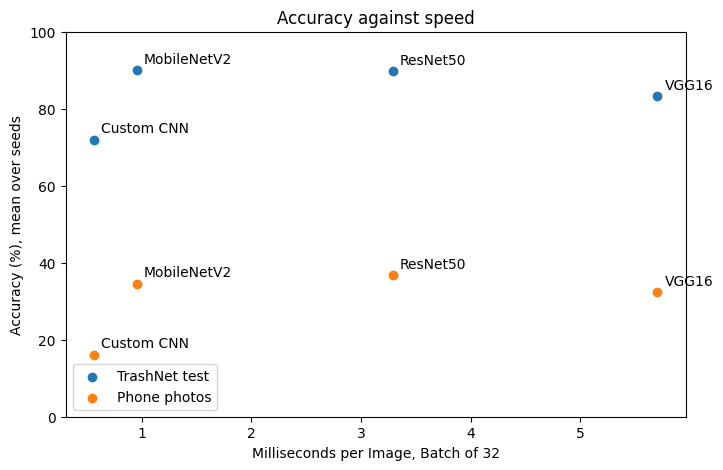

In [28]:
import matplotlib.pyplot as plt
import pandas as pd
from google.colab import drive

# Load saved results
drive.mount("/content/drive")
project_folder = "/content/drive/MyDrive/Waste_Classification_Project"
save_folder = f"{project_folder}/Evaluation"
summary_table = pd.read_csv(f"{save_folder}/eval_summary.csv")
size_speed_table = pd.read_csv(f"{save_folder}/eval_size_speed.csv")

# Average speed over seeds
speed_groups = size_speed_table.groupby("architecture")
time_groups = speed_groups["batch32_ms_per_image"]
mean_milliseconds = time_groups.mean()

# Plot accuracy against speed
display_names = {
    "customcnn": "Custom CNN",
    "vgg16": "VGG16",
    "resnet50": "ResNet50",
    "mobilenetv2": "MobileNetV2",
}
chart_sets = [
    ("trashnet_test", "TrashNet test"),
    ("phone_photos", "Phone photos"),
]
plt.figure(figsize=(8, 5))
for chart_set, set_label in chart_sets:
    chart_mask = summary_table["eval_set"] == chart_set
    chart_scores = summary_table[chart_mask]
    score_groups = chart_scores.groupby("architecture")
    accuracy_groups = score_groups["accuracy_percent"]
    mean_accuracy = accuracy_groups.mean()
    architectures = mean_accuracy.index
    set_milliseconds = mean_milliseconds.reindex(architectures)
    plt.scatter(set_milliseconds, mean_accuracy, label=set_label)
    for architecture in architectures:
        point_x = set_milliseconds[architecture]
        point_y = mean_accuracy[architecture]
        point = (point_x, point_y)
        plt.annotate(
            display_names[architecture],
            point,
            xytext=(5, 5),
            textcoords="offset points",
        )
plt.ylim(0, 100)
plt.xlabel("Milliseconds per Image, Batch of 32")
plt.ylabel("Accuracy (%), mean over seeds")
plt.title("Accuracy against speed")
plt.legend()
plt.show()